# Healthcare Appointment Attendance Analysis

## Project Objective

Analyze healthcare appointment records to identify
patterns associated with missed appointments.


## Key Questions

1. How does appointment lead time relate to no-show rates?
2. How do no-show rates differ across patient age groups?
3. How are SMS reminders associated with appointment attendance, overall and across appointment lead-time groups?
4. How do appointment no-show rates vary across weekdays?
5. How do no-show rates differ across neighborhoods, particularly those with the highest appointment volumes?


## Tools and Technologies

- **Python:** pandas, matplotlib
- **SQL:** SQLite
- **Visualization:** Tableau
- **Environment:** Jupyter Notebook


In [1]:
import pandas as pd

In [2]:
df = pd.read_csv('KaggleV2-May-2016.csv')

In [3]:
df.head()

,PatientId,AppointmentID,Gender,ScheduledDay,AppointmentDay,Age,Neighbourhood,Scholarship,Hipertension,Diabetes,Alcoholism,Handcap,SMS_received,No-show
0,2.987250e+13,5642903,F,2016-04-29T18:38:08Z,2016-04-29T00:00:00Z,62,JARDIM DA PENHA,0,1,0,0,0,0,No
1,5.589978e+14,5642503,M,2016-04-29T16:08:27Z,2016-04-29T00:00:00Z,56,JARDIM DA PENHA,0,0,0,0,0,0,No
2,4.262962e+12,5642549,F,2016-04-29T16:19:04Z,2016-04-29T00:00:00Z,62,MATA DA PRAIA,0,0,0,0,0,0,No
3,8.679512e+11,5642828,F,2016-04-29T17:29:31Z,2016-04-29T00:00:00Z,8,PONTAL DE CAMBURI,0,0,0,0,0,0,No
4,8.841186e+12,5642494,F,2016-04-29T16:07:23Z,2016-04-29T00:00:00Z,56,JARDIM DA PENHA,0,1,1,0,0,0,No


In [4]:
df.shape

(110527, 14)

In [5]:
df.dtypes

PatientId         float64
AppointmentID       int64
Gender             object
ScheduledDay       object
AppointmentDay     object
Age                 int64
Neighbourhood      object
Scholarship         int64
Hipertension        int64
Diabetes            int64
Alcoholism          int64
Handcap             int64
SMS_received        int64
No-show            object
dtype: object

In [6]:
print(df.shape[0])

110527


In [7]:
print(df.shape[1])

14


In [8]:
print("Column names:")
print(df.columns)

Column names:
Index(['PatientId', 'AppointmentID', 'Gender', 'ScheduledDay',
       'AppointmentDay', 'Age', 'Neighbourhood', 'Scholarship', 'Hipertension',
       'Diabetes', 'Alcoholism', 'Handcap', 'SMS_received', 'No-show'],
      dtype='object')


In [9]:
print("Missing values:")
df.isnull().sum()

Missing values:


PatientId         0
AppointmentID     0
Gender            0
ScheduledDay      0
AppointmentDay    0
Age               0
Neighbourhood     0
Scholarship       0
Hipertension      0
Diabetes          0
Alcoholism        0
Handcap           0
SMS_received      0
No-show           0
dtype: int64

In [10]:
print("\nDuplicate rows:")
df.duplicated().sum()


Duplicate rows:


0

In [11]:
print("\nDescriptive statistics:")
df.describe()


Descriptive statistics:


,PatientId,AppointmentID,Age,Scholarship,Hipertension,Diabetes,Alcoholism,Handcap,SMS_received
count,1.105270e+05,1.105270e+05,110527.000000,110527.000000,110527.000000,110527.000000,110527.000000,110527.000000,110527.000000
mean,1.474963e+14,5.675305e+06,37.088874,0.098266,0.197246,0.071865,0.030400,0.022248,0.321026
std,2.560949e+14,7.129575e+04,23.110205,0.297675,0.397921,0.258265,0.171686,0.161543,0.466873
min,3.921784e+04,5.030230e+06,-1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,4.172614e+12,5.640286e+06,18.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,3.173184e+13,5.680573e+06,37.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,9.439172e+13,5.725524e+06,55.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000
max,9.999816e+14,5.790484e+06,115.000000,1.000000,1.000000,1.000000,1.000000,4.000000,1.000000


## Initial Data Quality Assessment

- The dataset contains 110,527 records and 14 columns.
- No missing values were identified across the columns.
- No completely duplicated rows were identified.
- Numerical descriptive statistics were reviewed to understand the distributions and ranges of the numerical variables.

In [12]:
#age range of patients
df['Age'].describe()

count    110527.000000
mean         37.088874
std          23.110205
min          -1.000000
25%          18.000000
50%          37.000000
75%          55.000000
max         115.000000
Name: Age, dtype: float64

In [13]:
#Are there any patients with an age below 0 or above 100?

df[(df['Age'] < 0) | (df['Age'] > 100)].shape[0]

8

- The Age column contains values ranging from -1 to 115.
- Eight records have ages below 0 or above 100.
- Negative ages are invalid and require further investigation. Ages above 100 should be reviewed but are not necessarily erroneous.

In [14]:
df[df['Age'] < 0]

,PatientId,AppointmentID,Gender,ScheduledDay,AppointmentDay,Age,Neighbourhood,Scholarship,Hipertension,Diabetes,Alcoholism,Handcap,SMS_received,No-show
99832,4.659432e+14,5775010,F,2016-06-06T08:58:13Z,2016-06-06T00:00:00Z,-1,ROMÃO,0,0,0,0,0,0,No


In [15]:
#inspecting negative record
df.loc[df['Age'] < 0, ['PatientId', 'AppointmentID', 'Age', 'Gender', 'ScheduledDay', 'AppointmentDay']]

,PatientId,AppointmentID,Age,Gender,ScheduledDay,AppointmentDay
99832,4.659432e+14,5775010,-1,F,2016-06-06T08:58:13Z,2016-06-06T00:00:00Z


In [16]:
df[df['Age'] > 100]['Age'].value_counts()

Age
115    5
102    2
Name: count, dtype: int64

- One record contains an invalid negative age (-1).
- Seven records have ages above 100: two records with age 102 and five with age 115.
- Ages above 100 are unusual but cannot be classified as invalid based on age alone.

In [17]:
df[['ScheduledDay', 'AppointmentDay']].head()

,ScheduledDay,AppointmentDay
0,2016-04-29T18:38:08Z,2016-04-29T00:00:00Z
1,2016-04-29T16:08:27Z,2016-04-29T00:00:00Z
2,2016-04-29T16:19:04Z,2016-04-29T00:00:00Z
3,2016-04-29T17:29:31Z,2016-04-29T00:00:00Z
4,2016-04-29T16:07:23Z,2016-04-29T00:00:00Z


In [18]:
df[['ScheduledDay', 'AppointmentDay']].dtypes

ScheduledDay      object
AppointmentDay    object
dtype: object

In [19]:
#converting from object to datetime
df['ScheduledDay'] = pd.to_datetime(df['ScheduledDay'])
df['AppointmentDay'] = pd.to_datetime(df['AppointmentDay'])

In [20]:
df[['ScheduledDay', 'AppointmentDay']].dtypes

ScheduledDay      datetime64[ns, UTC]
AppointmentDay    datetime64[ns, UTC]
dtype: object

In [21]:
#investigate whether any appointments have a ScheduledDay later than their AppointmentDay
df[df['AppointmentDay'] < df['ScheduledDay']].shape[0]

38568

In [22]:
df.loc[
    df['AppointmentDay'] < df['ScheduledDay'],
    ['PatientId', 'AppointmentID', 'ScheduledDay', 'AppointmentDay']
].head(10)

,PatientId,AppointmentID,ScheduledDay,AppointmentDay
0,2.987250e+13,5642903,2016-04-29 18:38:08+00:00,2016-04-29 00:00:00+00:00
1,5.589978e+14,5642503,2016-04-29 16:08:27+00:00,2016-04-29 00:00:00+00:00
2,4.262962e+12,5642549,2016-04-29 16:19:04+00:00,2016-04-29 00:00:00+00:00
3,8.679512e+11,5642828,2016-04-29 17:29:31+00:00,2016-04-29 00:00:00+00:00
4,8.841186e+12,5642494,2016-04-29 16:07:23+00:00,2016-04-29 00:00:00+00:00
8,5.639473e+13,5638447,2016-04-29 08:02:16+00:00,2016-04-29 00:00:00+00:00
19,7.223289e+12,5640433,2016-04-29 10:43:14+00:00,2016-04-29 00:00:00+00:00
24,8.734858e+12,5641780,2016-04-29 14:19:19+00:00,2016-04-29 00:00:00+00:00
26,2.578785e+10,5641781,2016-04-29 14:19:42+00:00,2016-04-29 00:00:00+00:00
28,5.926172e+12,5642400,2016-04-29 15:48:02+00:00,2016-04-29 00:00:00+00:00


In [23]:
df['AppointmentDay'].dt.date < df['ScheduledDay'].dt.date

0         False
1         False
2         False
3         False
4         False
          ...  
110522    False
110523    False
110524    False
110525    False
110526    False
Length: 110527, dtype: bool

In [24]:
(df['AppointmentDay'].dt.date < df['ScheduledDay'].dt.date).sum()

5

In [25]:
df.loc[
    df['AppointmentDay'].dt.date < df['ScheduledDay'].dt.date,
    ['PatientId', 'AppointmentID', 'ScheduledDay', 'AppointmentDay']
]

,PatientId,AppointmentID,ScheduledDay,AppointmentDay
27033,7.839273e+12,5679978,2016-05-10 10:51:53+00:00,2016-05-09 00:00:00+00:00
55226,7.896294e+12,5715660,2016-05-18 14:50:41+00:00,2016-05-17 00:00:00+00:00
64175,2.425226e+13,5664962,2016-05-05 13:43:58+00:00,2016-05-04 00:00:00+00:00
71533,9.982316e+14,5686628,2016-05-11 13:49:20+00:00,2016-05-05 00:00:00+00:00
72362,3.787482e+12,5655637,2016-05-04 06:50:57+00:00,2016-05-03 00:00:00+00:00


In [26]:
df['LeadTime'] = (
    df['AppointmentDay'] - df['ScheduledDay']
).dt.total_seconds() / 86400

### Appointment Date Validation

- The initial timestamp comparison identified 38,568 potentially inconsistent records.
- Further investigation showed that most were same-day appointments where the scheduling timestamp included a time but the appointment timestamp was recorded at midnight.
- Comparing calendar dates reduced the number of inconsistent records to five.
- These five records have appointment dates earlier than their scheduling dates and require further investigation before cleaning.

In [27]:
df['LeadTime'] = (
    df['AppointmentDay'] - df['ScheduledDay']
).dt.total_seconds() / 86400

In [28]:
df['LeadTime'].describe()

count    110527.000000
mean          9.714284
std          15.244073
min          -6.575926
25%          -0.346163
50%           3.473819
75%          14.320538
max         178.554873
Name: LeadTime, dtype: float64

In [29]:
df['LeadTime'].head(10)

0   -0.776481
1   -0.672535
2   -0.679907
3   -0.728831
4   -0.671794
5    1.641076
6    1.371389
7    1.347245
8   -0.334907
9    1.466377
Name: LeadTime, dtype: float64

In [30]:
#checking for negative lead times
(df['LeadTime'] < 0).sum()

38568

In [31]:
#distribution of negative values
df.loc[df['LeadTime'] < 0, 'LeadTime'].sort_values()

71533    -6.575926
55226    -1.618530
64175    -1.572199
27033    -1.452697
72362    -1.285382
            ...   
103998   -0.268588
103953   -0.267569
76603    -0.266956
75346    -0.257488
75347    -0.256667
Name: LeadTime, Length: 38568, dtype: float64

In [32]:
#Calculate the number of calendar days between the scheduled date and appointment date,
#without letting the time of day affect the result

df['LeadTimeDays'] = df['AppointmentDay'].dt.date - df['ScheduledDay'].dt.date
print(df['LeadTimeDays'])

0                  0:00:00
1                  0:00:00
2                  0:00:00
3                  0:00:00
4                  0:00:00
                ...       
110522    35 days, 0:00:00
110523    35 days, 0:00:00
110524    41 days, 0:00:00
110525    41 days, 0:00:00
110526    41 days, 0:00:00
Name: LeadTimeDays, Length: 110527, dtype: object


In [33]:
df['LeadTimeDays'] = pd.to_timedelta(df['LeadTimeDays'])

In [34]:
df['LeadTimeDays'].min()

Timedelta('-6 days +00:00:00')

In [35]:
df['LeadTimeDays'].max()

Timedelta('179 days 00:00:00')

In [36]:
df[df['LeadTimeDays'] < pd.Timedelta(days=0)].shape[0]

5

In [37]:
cleaned_df = df.copy()

In [38]:
cleaned_df = cleaned_df[cleaned_df['LeadTimeDays'] >= pd.Timedelta(days=0)]

In [39]:
cleaned_df.shape

(110522, 16)

In [40]:
(cleaned_df['LeadTimeDays'] < pd.Timedelta(days=0)).sum()

0

### Handling Invalid Appointment Dates
- Identified five records where the appointment date occurred before the scheduling date.
- Excluded these five records from the cleaned analysis dataset because their lead times were invalid.
- Preserved the original dataset (`df`) and created a separate cleaned dataset (`cleaned_df`).
- The cleaned dataset contains 110,522 records and 16 columns.
- Verified that no negative lead times remain.

### Validate Target Variable

In [41]:
cleaned_df['No-show'].unique()

array(['No', 'Yes'], dtype=object)

In [42]:
cleaned_df['No-show'].value_counts()

No-show
No     88208
Yes    22314
Name: count, dtype: int64

### Appointment Outcome Distribution
- The cleaned dataset contains 110,522 appointments.
- 88,208 appointments (79.8%) were attended.
- 22,314 appointments (20.2%) were missed.
- Approximately one in five appointments resulted in a no-show.

### Calculating no-show rate

In [43]:
no_show_rate = (cleaned_df['No-show'] == 'Yes').sum() / cleaned_df.shape[0]

In [44]:
no_show_rate * 100

20.18964550044335

### Does waiting longer relate to missed appointments?

In [45]:
cleaned_df['LeadTimeDays'].describe()

count                        110522
mean     10 days 04:25:19.451330956
std      15 days 06:07:21.956876522
min                 0 days 00:00:00
25%                 0 days 00:00:00
50%                 4 days 00:00:00
75%                15 days 00:00:00
max               179 days 00:00:00
Name: LeadTimeDays, dtype: object

### Creating lead time groups

In [46]:
cleaned_df['LeadTimeGroup'] = pd.cut(
    cleaned_df['LeadTimeDays'].dt.days,
    bins=[-1, 0, 7, 30, 179],
    labels=['Same day', 'Short', 'Medium', 'Long']
)

In [47]:
cleaned_df['LeadTimeGroup'].value_counts().sort_index()

LeadTimeGroup
Same day    38563
Short       32185
Medium      29396
Long        10378
Name: count, dtype: int64

### Comparing no-show rates by lead-time group

In [48]:
(cleaned_df['No-show'] == 'Yes').groupby(
    cleaned_df['LeadTimeGroup'],
    observed=False
).mean()

LeadTimeGroup
Same day    0.046469
Short       0.241479
Medium      0.317220
Long        0.330025
Name: No-show, dtype: float64

Appointment no-show rates increased with longer scheduling lead times. Same-day appointments had a 4.65% no-show rate, compared with 24.15% for appointments scheduled 1–7 days in advance, 31.72% for 8–30 days, and 33.00% for 31+ days. The highest no-show rates occurred among appointments scheduled more than a month in advance. These results indicate an association between longer scheduling lead times and missed appointments, but do not establish causation.

### No-show rates by day of the week

In [49]:
cleaned_df['AppointmentWeekday'] = cleaned_df['AppointmentDay'].dt.day_name()

In [50]:
cleaned_df['AppointmentWeekday'].value_counts()

AppointmentWeekday
Wednesday    25866
Tuesday      25638
Monday       22714
Friday       19019
Thursday     17246
Saturday        39
Name: count, dtype: int64

In [51]:
(cleaned_df['No-show'] == 'Yes').groupby(cleaned_df['AppointmentWeekday']).mean()

AppointmentWeekday
Friday       0.212261
Monday       0.206437
Saturday     0.230769
Thursday     0.193494
Tuesday      0.200874
Wednesday    0.196861
Name: No-show, dtype: float64

No-show rates varied modestly across weekdays, ranging from 19.35% on Thursday to 21.23% on Friday. Saturday had a higher observed rate of 23.08%, but represented only 39 appointments, making this estimate unreliable. Overall, weekday differences were relatively small.

### SMS reminders

In [52]:
cleaned_df['SMS_received'].value_counts()

SMS_received
0    75040
1    35482
Name: count, dtype: int64

In [53]:
(cleaned_df['No-show'] == 'Yes').groupby(cleaned_df['SMS_received']).mean()

SMS_received
0    0.166978
1    0.275745
Name: No-show, dtype: float64

Appointments with an SMS reminder recorded had a higher no-show rate (27.57%) than appointments without an SMS reminder (16.70%). This association does not establish that SMS reminders increase no-shows. Differences in scheduling lead time, patient characteristics, or reminder assignment practices may influence the observed relationship.

In [54]:
cleaned_df['SMS_received'].groupby(
    cleaned_df['LeadTimeGroup'],
    observed=False
).mean()

LeadTimeGroup
Same day    0.000000
Short       0.358801
Medium      0.596136
Long        0.617653
Name: SMS_received, dtype: float64

SMS reminder prevalence increased with appointment lead time. No same-day appointments in the cleaned dataset had an SMS reminder recorded, compared with 35.88% of appointments scheduled 1–7 days in advance and approximately 60–62% of appointments scheduled more than a week in advance. This suggests that scheduling lead time may influence the observed relationship between SMS reminders and no-shows.

### Comparing SMS and no-shows within lead-time groups

In [55]:
cleaned_df['IsNoShow'] = cleaned_df['No-show'] == 'Yes'

In [56]:
pd.pivot_table(
    cleaned_df,
    index='LeadTimeGroup',
    columns='SMS_received',
    values='IsNoShow',
    aggfunc='mean',
    observed=False
)

SMS_received,0,1
LeadTimeGroup,,
Same day,0.046469,NaN
Short,0.243640,0.237617
Medium,0.355542,0.291258
Long,0.375252,0.302028


### SMS Reminders and Lead Time
- Overall, appointments with SMS reminders had a higher no-show rate than appointments without reminders.
- When comparing appointments within the same lead-time group, SMS recipients had similar or lower no-show rates than non-recipients.
- The difference was minimal for short lead times, while medium- and long-lead-time appointments showed lower no-show rates among SMS recipients.
- Lead time may help explain the difference observed in the overall SMS comparison.
- These findings show an association and do not establish that SMS reminders cause lower no-show rates.

In [57]:
cleaned_df[cleaned_df['Age'] < 0].shape[0]

1

In [58]:
age_df = cleaned_df.copy()
age_df = age_df[age_df['Age'] >= 0]

In [59]:
age_df.shape

(110521, 19)

In [60]:
age_df['AgeGroup'] = pd.cut(
    age_df['Age'],
    bins=[-1, 17, 34, 54, 74, 115],
    labels=['Children', 'Young adults', 'Adults', 'Older adults', 'Seniors']
)

In [61]:
age_df['AgeGroup'].value_counts().sort_index()

AgeGroup
Children        27378
Young adults    24244
Adults          29971
Older adults    22993
Seniors          5935
Name: count, dtype: int64

In [62]:
age_rates = age_df.groupby('AgeGroup', observed=False)['IsNoShow'].mean()
age_rates

AgeGroup
Children        0.219008
Young adults    0.239729
Adults          0.198425
Older adults    0.156961
Seniors         0.160067
Name: IsNoShow, dtype: float64

### Analyze no-show rates by age group

In [63]:
age_df['IsNoShow'].groupby(age_df['AgeGroup'], observed=False).mean()

AgeGroup
Children        0.219008
Young adults    0.239729
Adults          0.198425
Older adults    0.156961
Seniors         0.160067
Name: IsNoShow, dtype: float64

### No-Show Rates by Age Group

- Young adults (18–34) had the highest no-show rate at 23.97%, followed by children (0–17) at 21.90%.
- Adults aged 35–54 had a no-show rate of 19.84%.
- Older adults (55–74) had the lowest no-show rate at 15.70%.
- Seniors (75–115) had a no-show rate of 16.01%, slightly higher than the 55–74 group.
- Overall, younger age groups had higher observed no-show rates than older age groups.

These results suggest an association between patient age and appointment attendance, but do not establish why these differences occur.


In [64]:
cleaned_df['Neighbourhood'].nunique()

81

In [65]:
top10_neighbourhoods = cleaned_df['Neighbourhood'].value_counts().head(10)

In [66]:
neighbourhood_rates = cleaned_df['IsNoShow'].groupby(cleaned_df['Neighbourhood']).mean()

In [67]:
neighbourhood_rates

Neighbourhood
AEROPORTO              0.125000
ANDORINHAS             0.230327
ANTÔNIO HONÓRIO        0.184502
ARIOVALDO FAVALESSA    0.219858
BARRO VERMELHO         0.215130
                         ...   
SÃO JOSÉ               0.216490
SÃO PEDRO              0.210376
TABUAZEIRO             0.182689
UNIVERSITÁRIO          0.210526
VILA RUBIM             0.165687
Name: IsNoShow, Length: 81, dtype: float64

In [68]:
neighbourhood_rates.loc[top10_neighbourhoods.index]

Neighbourhood
JARDIM CAMBURI       0.189841
MARIA ORTIZ          0.209991
RESISTÊNCIA          0.204289
JARDIM DA PENHA      0.162755
ITARARÉ              0.262664
CENTRO               0.210858
TABUAZEIRO           0.182689
SANTA MARTHA         0.158416
JESUS DE NAZARETH    0.243954
BONFIM               0.198341
Name: IsNoShow, dtype: float64

### Neighborhood Analysis
- Compared no-show rates among the 10 neighborhoods with the highest appointment volumes.
- Itararé had the highest no-show rate among these neighborhoods (26.27%), followed by Jesus de Nazareth (24.40%).
- Santa Martha had the lowest rate (15.84%).
- No-show rates varied by neighborhood despite all 10 neighborhoods having relatively large appointment volumes.
- Jardim Camburi had the highest appointment volume (7,717) but a no-show rate of 18.98%, below the overall dataset rate of 20.19%.
- Neighborhood-level differences may warrant further investigation, but this analysis does not establish why rates differ.

In [69]:
import matplotlib.pyplot as plt

### Data Visualization

In [70]:
leadtime_rates = cleaned_df['IsNoShow'].groupby(
    cleaned_df['LeadTimeGroup'],
    observed=False
).mean()

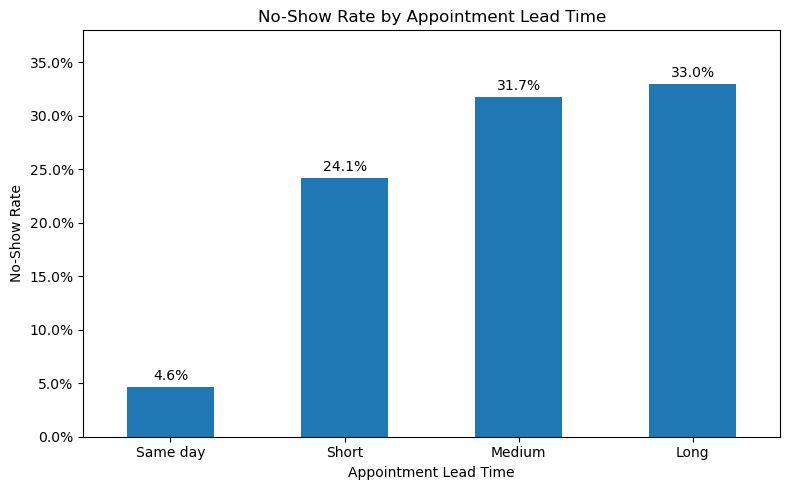

In [71]:
from matplotlib.ticker import PercentFormatter

ax = leadtime_rates.plot(kind='bar', figsize=(8, 5))

ax.set_title('No-Show Rate by Appointment Lead Time')
ax.set_xlabel('Appointment Lead Time')
ax.set_ylabel('No-Show Rate')

ax.yaxis.set_major_formatter(PercentFormatter(1))
ax.bar_label(
    ax.containers[0],
    labels=[f'{value:.1%}' for value in leadtime_rates],
    padding=3
)

ax.tick_params(axis='x', rotation=0)
ax.set_ylim(0, 0.38)

plt.tight_layout()
plt.show()

In [72]:
age_rates = age_df['IsNoShow'].groupby(
    age_df['AgeGroup'],
    observed=False
).mean()

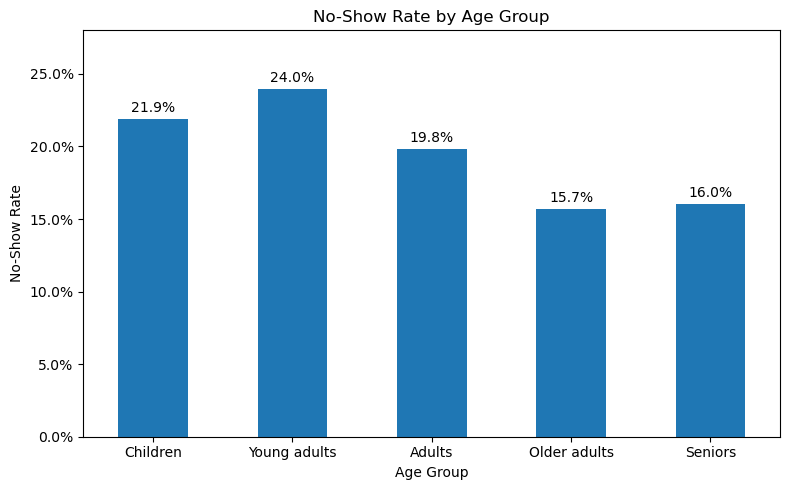

In [73]:
ax = age_rates.plot(kind='bar', figsize=(8, 5))

ax.set_title('No-Show Rate by Age Group')
ax.set_xlabel('Age Group')
ax.set_ylabel('No-Show Rate')

ax.yaxis.set_major_formatter(PercentFormatter(1))
ax.bar_label(
    ax.containers[0],
    labels=[f'{value:.1%}' for value in age_rates],
    padding=3
)

ax.tick_params(axis='x', rotation=0)
ax.set_ylim(0, 0.28)

plt.tight_layout()
plt.show()

In [74]:
sms_leadtime_rates = pd.pivot_table(
    cleaned_df,
    index='LeadTimeGroup',
    columns='SMS_received',
    values='IsNoShow',
    aggfunc='mean',
    observed=False
)

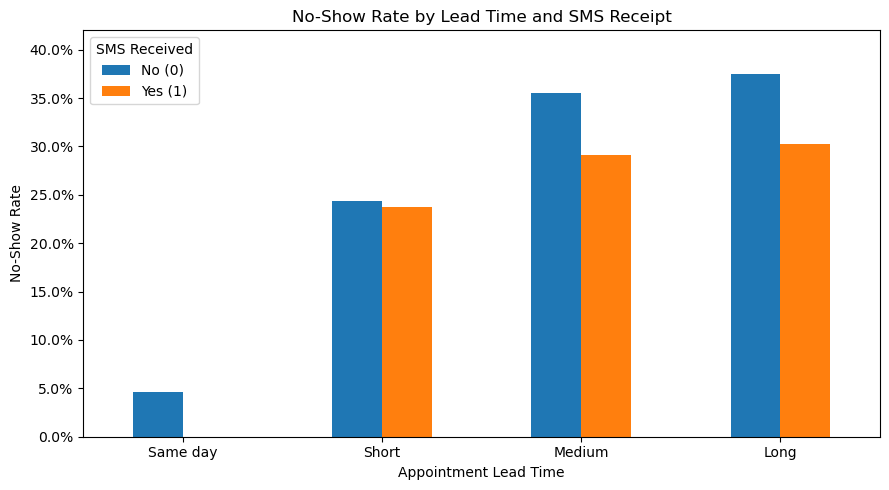

In [75]:
ax = sms_leadtime_rates.plot(
    kind='bar',
    figsize=(9, 5)
)

ax.set_title('No-Show Rate by Lead Time and SMS Receipt')
ax.set_xlabel('Appointment Lead Time')
ax.set_ylabel('No-Show Rate')

ax.yaxis.set_major_formatter(PercentFormatter(1))

ax.tick_params(axis='x', rotation=0)
ax.legend(title='SMS Received', labels=['No (0)', 'Yes (1)'])

ax.set_ylim(0, 0.42)

plt.tight_layout()
plt.show()

In [76]:
neighbourhood_chart = neighbourhood_rates.loc[
    top10_neighbourhoods.index
].sort_values()

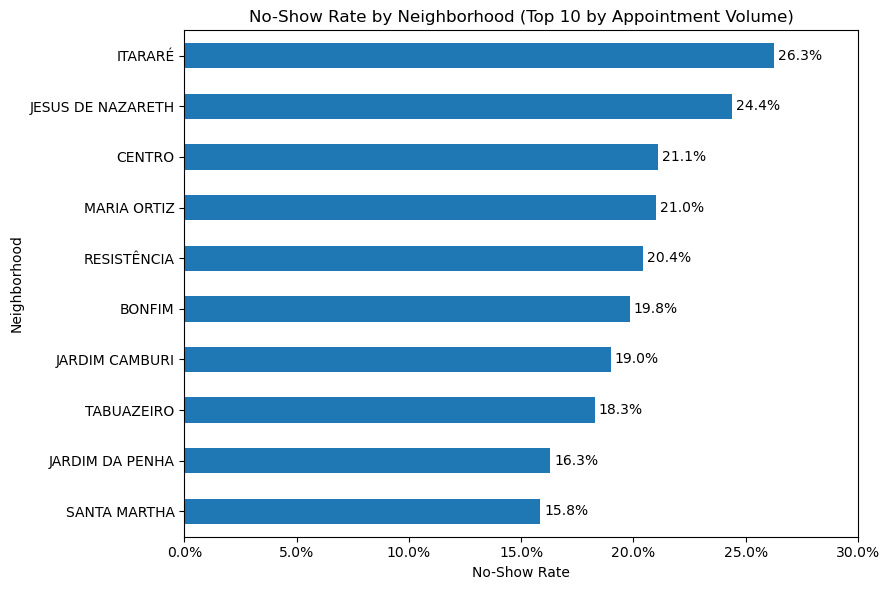

In [77]:
ax = neighbourhood_chart.plot(
    kind='barh',
    figsize=(9, 6)
)

ax.set_title('No-Show Rate by Neighborhood (Top 10 by Appointment Volume)')
ax.set_xlabel('No-Show Rate')
ax.set_ylabel('Neighborhood')

ax.xaxis.set_major_formatter(PercentFormatter(1))

ax.bar_label(
    ax.containers[0],
    labels=[f'{value:.1%}' for value in neighbourhood_chart],
    padding=3
)

ax.set_xlim(0, 0.30)

plt.tight_layout()
plt.show()

### SQL Analysis

In [78]:
import sqlite3
conn = sqlite3.connect('appointments.db')

In [79]:
sql_df = cleaned_df.copy()

sql_df['LeadTimeDays'] = sql_df['LeadTimeDays'].dt.days

sql_df.to_sql(
    'appointments',
    conn,
    if_exists='replace',
    index=False
)

110522

### Which appointment lead-time groups have the highest no-show rates?

In [80]:
leadtime_query = """ SELECT
    LeadTimeGroup,
    COUNT(*) AS TotalAppointments,
    SUM(
        CASE
            WHEN "No-show" = 'Yes' THEN 1
            ELSE 0
        END
    ) AS NoShows,
    SUM(
        CASE
            WHEN "No-show" = 'Yes' THEN 1
            ELSE 0
        END
    ) * 1.0 / COUNT(*) AS NoShowRate
FROM appointments
GROUP BY LeadTimeGroup
ORDER BY
    CASE LeadTimeGroup
        WHEN 'Same day' THEN 1
        WHEN 'Short' THEN 2
        WHEN 'Medium' THEN 3
        WHEN 'Long' THEN 4
    END;
"""

pd.read_sql_query(leadtime_query, conn)

,LeadTimeGroup,TotalAppointments,NoShows,NoShowRate
0,Same day,38563,1792,0.046469
1,Short,32185,7772,0.241479
2,Medium,29396,9325,0.317220
3,Long,10378,3425,0.330025


### Do appointment no-show rates differ between patients who received an SMS reminder and those who did not?

In [81]:
sms_query = """ SELECT
    SMS_received,
    COUNT(*) AS TotalAppointments,
    SUM(
        CASE
            WHEN "No-show" = 'Yes' THEN 1
            ELSE 0
        END
    ) AS NoShows,
    SUM(
        CASE
            WHEN "No-show" = 'Yes' THEN 1
            ELSE 0
        END
    ) * 1.0 / COUNT(*) AS NoShowRate
FROM appointments
GROUP BY SMS_received
ORDER BY SMS_received;
"""

pd.read_sql_query(sms_query, conn)

,SMS_received,TotalAppointments,NoShows,NoShowRate
0,0,75040,12530,0.166978
1,1,35482,9784,0.275745


### Does the SMS pattern change by lead time?

In [82]:
sms_leadtime_query = """
SELECT
    LeadTimeGroup,
    SMS_received,
    COUNT(*) AS TotalAppointments,
    SUM(
        CASE
            WHEN "No-show" = 'Yes' THEN 1
            ELSE 0
        END
    ) AS NoShows,
    SUM(
        CASE
            WHEN "No-show" = 'Yes' THEN 1
            ELSE 0
        END
    ) * 1.0 / COUNT(*) AS NoShowRate
FROM appointments
GROUP BY LeadTimeGroup, SMS_received;
"""

pd.read_sql_query(sms_leadtime_query, conn)

,LeadTimeGroup,SMS_received,TotalAppointments,NoShows,NoShowRate
0,Long,0,3968,1489,0.375252
1,Long,1,6410,1936,0.302028
2,Medium,0,11872,4221,0.355542
3,Medium,1,17524,5104,0.291258
4,Same day,0,38563,1792,0.046469
5,Short,0,20637,5028,0.243640
6,Short,1,11548,2744,0.237617


### Which weekdays have the highest no-show rates?

In [83]:
weekday_query = """
SELECT
    strftime('%w', AppointmentDay) AS weekday,
    CASE strftime('%w', AppointmentDay)
        WHEN '0' THEN 'Sunday'
        WHEN '1' THEN 'Monday'
        WHEN '2' THEN 'Tuesday'
        WHEN '3' THEN 'Wednesday'
        WHEN '4' THEN 'Thursday'
        WHEN '5' THEN 'Friday'
        WHEN '6' THEN 'Saturday'
    END AS weekday_name,
    COUNT(*) AS TotalAppointments,
    SUM(
        CASE
            WHEN "No-show" = 'Yes' THEN 1
            ELSE 0
        END
    ) AS NoShows,
    SUM(
        CASE
            WHEN "No-show" = 'Yes' THEN 1
            ELSE 0
        END
    ) * 1.0 / COUNT(*) AS NoShowRate
FROM appointments
GROUP BY strftime('%w', AppointmentDay)
ORDER BY weekday;
"""

pd.read_sql_query(weekday_query, conn)

,weekday,weekday_name,TotalAppointments,NoShows,NoShowRate
0,1,Monday,22714,4689,0.206437
1,2,Tuesday,25638,5150,0.200874
2,3,Wednesday,25866,5092,0.196861
3,4,Thursday,17246,3337,0.193494
4,5,Friday,19019,4037,0.212261
5,6,Saturday,39,9,0.230769


### No-show rates by age group

In [84]:
no_show_age_query = """ WITH age_analysis AS (
    SELECT 
        "No-show",
        CASE 
            WHEN Age BETWEEN 0 AND 17 THEN 'Children'
            WHEN Age BETWEEN 18 AND 34 THEN 'Young adults'
            WHEN Age BETWEEN 35 AND 54 THEN 'Adults'
            WHEN Age BETWEEN 55 AND 74 THEN 'Older Adults'
            WHEN Age BETWEEN 75 AND 115 THEN 'Seniors'
        END AS AgeGroup
    FROM appointments
    WHERE Age >= 0
)

SELECT
    AgeGroup,
    COUNT(*) AS TotalAppointments,
    SUM(
        CASE
            WHEN "No-show" = 'Yes' THEN 1
            ELSE 0
        END
    ) AS NoShows,
    SUM(
        CASE
            WHEN "No-show" = 'Yes' THEN 1
            ELSE 0
        END
    ) * 1.0 / COUNT(*) AS NoShowRate
FROM age_analysis
GROUP BY AgeGroup;
"""

pd.read_sql_query(no_show_age_query, conn)

,AgeGroup,TotalAppointments,NoShows,NoShowRate
0,Adults,29971,5947,0.198425
1,Children,27378,5996,0.219008
2,Older Adults,22993,3609,0.156961
3,Seniors,5935,950,0.160067
4,Young adults,24244,5812,0.239729


### Neighborhood analysis

In [85]:
neighborhood_query = """
WITH neighborhood_stats AS (
    SELECT
        Neighbourhood,
        COUNT(*) AS TotalAppointments,
        SUM(
            CASE
                WHEN "No-show" = 'Yes' THEN 1
                ELSE 0
            END
        ) AS NoShows,
        SUM(
            CASE
                WHEN "No-show" = 'Yes' THEN 1
                ELSE 0
            END
        ) * 1.0 / COUNT(*) AS NoShowRate
    FROM appointments
    GROUP BY Neighbourhood
)

SELECT *,
    RANK() OVER (
        ORDER BY TotalAppointments DESC
    ) AS VolumeRank
FROM neighborhood_stats
ORDER BY VolumeRank;
"""

pd.read_sql_query(neighborhood_query, conn)

,Neighbourhood,TotalAppointments,NoShows,NoShowRate,VolumeRank
0,JARDIM CAMBURI,7717,1465,0.189841,1
1,MARIA ORTIZ,5805,1219,0.209991,2
2,RESISTÊNCIA,4430,905,0.204289,3
3,JARDIM DA PENHA,3877,631,0.162755,4
4,ITARARÉ,3514,923,0.262664,5
...,...,...,...,...,...
76,ILHA DO BOI,35,3,0.085714,77
77,ILHA DO FRADE,10,2,0.200000,78
78,AEROPORTO,8,1,0.125000,79
79,ILHAS OCEÂNICAS DE TRINDADE,2,2,1.000000,80


# Tableau Dashboard Preparation

In [86]:
tableau_df = age_df.copy()

tableau_df.to_csv('appointments_tableau.csv', index=False)

In [87]:
tableau_df.shape

(110521, 20)

### Preparing Data for Tableau

The cleaned dataset was exported from Python as a CSV file for use in Tableau. The export included the cleaned appointment records and derived fields used in the analysis, including appointment lead time, lead-time groups, appointment weekdays, no-show indicators, and age groups.

One record with an invalid negative age was excluded from the Tableau dataset, resulting in 110,521 records. The general appointment analysis used 110,522 records because this record was excluded only from the age-related analysis and Tableau preparation.


## Key Findings and Recommendations


### Key Finding: Appointment Lead Time and No-Show Rates

No-show rates increased as the time between scheduling and the appointment increased.

- Same day (0 days): 4.65%
- Short (1–7 days): 24.15%
- Medium (8–30 days): 31.72%
- Long (31–179 days): 33.00%

Appointments scheduled on the same day had a considerably lower no-show rate than appointments scheduled in advance. The largest increase occurred between same-day and short-lead-time appointments.

This pattern suggests that longer scheduling lead times are associated with higher no-show rates. Healthcare providers could explore additional reminders, appointment confirmation processes, or waitlist strategies for appointments scheduled further in advance.

However, this analysis identifies an association and does not establish that appointment lead time directly causes no-shows.


### Key Finding: No-Show Rates by Age Group

Young adults (18–34) had the highest no-show rate at 23.97%, while older adults (55–74) had the lowest at 15.70%.

Overall, younger age groups had higher no-show rates than older age groups. This suggests that age-related differences may be worth considering when designing appointment engagement strategies.

However, the relationship was not strictly linear, as seniors (75–115) had a slightly higher no-show rate than older adults. This analysis identifies an association but does not establish why patients miss appointments.


### Key Finding: SMS Reminders and No-Show Rates

Patients who received an SMS reminder had a higher overall no-show rate (27.57%) than patients who did not receive one (16.70%), a difference of 10.88 percentage points.

However, when comparing patients within the same appointment lead-time groups, the pattern changed. For short-, medium-, and long-lead-time appointments, patients who received SMS reminders had lower no-show rates than those who did not.

This suggests that the overall relationship between SMS receipt and no-shows may be influenced by appointment lead time and differences in which patients received reminders.

These results show an association, not a causal effect. The analysis does not establish whether SMS reminders prevent missed appointments.


### Key Finding: No-Show Rates by Weekday

No-show rates varied slightly by weekday, ranging from 19.35% on Thursday to 21.23% on Friday. Saturday had the highest no-show rate at 23.08%, but only 39 appointments were scheduled on Saturdays, making this result less representative. Overall, weekday differences were relatively small, suggesting that weekday alone may not be a strong indicator of missed appointments.

### Key Finding: No-Show Rates by Neighborhood

Among the 10 neighborhoods with the highest appointment volumes, no-show rates varied considerably.

Itararé had the highest no-show rate at 26.27%, while Santa Martha had the lowest at 15.84%, a difference of 10.43 percentage points.

Jardim Camburi had the highest appointment volume among these neighborhoods, with 7,717 appointments, and a no-show rate of 18.98%, below the overall dataset rate of 20.19%.

These differences suggest that appointment attendance patterns vary across neighborhoods. However, the analysis does not establish what factors contribute to these geographic differences.


## Overall Conclusion

This analysis examined factors associated with medical appointment no-shows using approximately 110,500 appointment records.

Appointment lead time showed the largest differences in no-show rates. Appointments scheduled further in advance had substantially higher no-show rates than same-day appointments. Differences were also observed across age groups and neighborhoods, with no-show rates varying by patient age and neighborhood. Weekday differences were relatively small.

The SMS analysis revealed an important distinction: although patients who received SMS reminders had a higher overall no-show rate, comparisons within appointment lead-time groups showed lower no-show rates among patients who received reminders for short-, medium-, and long-lead-time appointments. This highlights the importance of considering multiple variables when interpreting aggregate results.

Overall, the findings suggest that appointment lead time, patient age, SMS receipt, and neighborhood are useful dimensions for understanding attendance patterns, while weekday alone showed relatively limited variation. However, these relationships are observational and do not establish causation.


## Recommendations

Based on the observed patterns, healthcare providers could consider exploring the following strategies:

1. **Prioritize appointments scheduled further in advance:** Evaluate additional reminder or confirmation processes for appointments with longer lead times.

2. **Explore age-informed engagement strategies:** Investigate whether younger patient groups would benefit from different appointment communication or engagement approaches.

3. **Evaluate SMS reminder effectiveness:** Examine reminder timing, delivery, and patient characteristics to better understand how SMS reminders relate to attendance.

4. **Investigate neighborhood-level differences:** Explore whether transportation access, appointment availability, or other community-level factors may help explain differences in attendance patterns.

5. **Monitor weekday attendance patterns:** Continue monitoring no-show rates across weekdays to determine whether small differences persist over time, while avoiding conclusions based on days with limited appointment volume.

These recommendations are areas for further investigation rather than proven interventions. Additional data and controlled evaluation would be needed to determine their effectiveness.


## Limitations

Several limitations should be considered when interpreting these findings:

1. **Observational data:** This analysis identifies associations between appointment characteristics and no-show rates but cannot establish causation.
2. **SMS reminder information:** The dataset indicates whether an SMS reminder was received but does not provide details about reminder timing, delivery status, or whether patients read the message. Differences between patients who received and did not receive reminders may also influence the observed results.
3. **Limited patient context:** Factors such as transportation access, employment schedules, socioeconomic circumstances, and reasons for missed appointments are not included.
4. **Geographic analysis:** Neighborhood-level differences do not explain the underlying reasons for variation in attendance. The analysis focuses on the 10 neighborhoods with the highest appointment volumes rather than all neighborhoods.
5. **Data quality:** Five records with appointment dates preceding their scheduling dates were excluded. One record with an invalid negative age was also excluded from the age analysis.